# Softcite, Baguette and bio2flow on the PEPR corpus: what each one finds

Three extractors ran on the same 264 PEPR Santé Numérique papers. This notebook compares **which software each one finds in each paper**, where they agree, where they don't, and what the disagreements are made of.

| Tool | What it is | Input | Output used here |
|---|---|---|---|
| **Softcite** | `software-mentions` 0.9.0, a fine-tuned SciBERT + CRF | GROBID TEI | `softcite/*.software.json` |
| **Baguette** | the dataESR LLM pipeline (paragraph classification, then extraction) | GROBID TEI paragraphs | `baguette_softcite/*.software.json`, from `scripts/baguette_to_softcite.py` |
| **bio2flow** | the CoPaLink paper-text NER (`Tool` entities), trained on bioinformatics workflows | the GROBID TEI paragraphs | `bio2flow_softcite/*.software.json`, from a re-run of `scripts/copalink_client.py` (see below) |

**There are no gold annotations on this corpus.** Agreement is not correctness: three tools can agree on a wrong answer, and a software found by one tool only can be right. Section 8 has a cheap LLM judge (Claude Haiku) label a sample of the disagreements, to estimate how many of the software found by one tool only are real.

**Unit of comparison: a software in a paper.** The tools count mentions differently (Softcite and bio2flow report every occurrence; Baguette reports each software once per paper with one evidence sentence), so we compare the **set of software names each tool finds in each paper**.

### Summary (run of 2026-10-15)

- **The tools mostly disagree.** On the 263 papers, 4,083 (paper, software) pairs are found by at least one tool (loose name matching), and only 501 (12%) by all three. The Jaccard index is 0.35 between Softcite and Baguette, 0.27 between Softcite and bio2flow, and 0.18 between Baguette and bio2flow.
- **Softcite and Baguette agree on which papers mention software, and on how many** (Spearman 0.85 on the counts per paper). bio2flow finds the most software (2,565 groups) and many more distinct names.
- **What each tool finds alone:** Softcite finds programming languages and libraries (Python, NumPy, pandas), plus generic words tagged as software (code, scripts). Baguette finds R in 34 papers where the others don't, plus platforms (Zenodo, GitHub). bio2flow finds methods and acronyms (LASSO, SHAP, ReLU, gene names).
- **What the judge says** (Claude Haiku, 285 sampled items): 77% of the consensus software and 84% of the Softcite + Baguette software are real software. So are 37% of Softcite's single-tool finds and 32% of Baguette's, but only 2% of bio2flow's. Estimated precision: Softcite 0.56, Baguette 0.59, bio2flow 0.23. Estimated share of the real software found by any tool: Softcite 0.81, Baguette 0.72, bio2flow 0.45.
- **bio2flow's published output is damaged** for 61 papers; this notebook uses a re-run (see the input note).

> **Input.** The three folders under `data/pepr-hal-data/`. Get `softcite/`, `baguette/` and `bio2flow/` from 🤗 [`HackatonSanteNumerique/pepr-hal-data`](https://huggingface.co/datasets/HackatonSanteNumerique/pepr-hal-data), then convert the last two to the Softcite schema:
>
> ```bash
> uv run python scripts/download_pepr.py --pattern "softcite/*" --pattern "baguette/*" --pattern "bio2flow/*"
> cd scripts
> ./run_baguette_to_softcite.sh ../data/pepr-hal-data/baguette ../data/pepr-hal-data/baguette_softcite
> ./run_ann_to_softcite.sh ../data/pepr-hal-data/bio2flow ../data/pepr-hal-data/bio2flow_softcite
> ```
>
> The notebook also accepts the folder names of `scripts/run_merge.sh` (`softcite_from_baguette`, `softcite_from_bio2flow`).
>
> **bio2flow: use a re-run.** The `bio2flow/` and `bio2flow_json/` outputs on 🤗 (as of 2026-10-15) are damaged for 61 of the 264 papers: 48 have no entity at all (including papers where Softcite finds 30 software) and 13 have far fewer than they should (3 instead of 83). The endpoint gives the right result for those papers today, so we re-ran the 264 papers and wrote them in the Softcite schema with the client's own `to_softcite`:
>
> ```bash
> uv run python scripts/copalink_client.py --input-folder <one .json list of paragraphs per paper> \
>     --output-dir data/pepr-hal-data/bio2flow_json_rerun --softcite-dir data/pepr-hal-data/bio2flow_softcite \
>     --endpoint https://sciencialab--bio2flow-app-extract-endpoint.modal.run --threads 6
> ```
>
> The paragraphs are those of `bio2flow_json/` (the GROBID TEI paragraphs). The contexts are then whole paragraphs, not sentences; the judge sample (section 7) cuts a window around the name.

## 0 — Setup

In [1]:
import json
import math
import re
import unicodedata
from collections import Counter
from itertools import combinations
from pathlib import Path

import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

# The data lives in <repo>/data/pepr-hal-data; this notebook lives in notebooks/.
ROOT = Path(".") if Path("data/pepr-hal-data").exists() else Path("..")
PEPR = ROOT / "data/pepr-hal-data"
JUDGE_DIR = ROOT / "notebooks/extractor_judge"

FOLDERS = {
    "softcite": ["softcite"],
    "baguette": ["baguette_softcite", "softcite_from_baguette"],
    "bio2flow": ["bio2flow_softcite", "softcite_from_bio2flow"],
}
TOOLS = list(FOLDERS)
DIRS = {}
for tool, names in FOLDERS.items():
    found = [PEPR / n for n in names if (PEPR / n).is_dir()]
    assert found, f"No folder for {tool} in {PEPR}: expected one of {names} (see the input note above)"
    DIRS[tool] = found[0]

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)

# --- chart style (same as softcite_analysis.ipynb) ------------------------------
THEME = "light"
STYLE = {
    "light": dict(surface="#fcfcfb", ink="#0b0b0b", ink2="#52514e", muted="#898781", grid="#e1e0d9", axis="#c3c2b7",
                  series=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]),
    "dark": dict(surface="#1a1a19", ink="#f0efec", ink2="#c3c2b7", muted="#898781", grid="#2c2c2a", axis="#383835",
                 series=["#3987e5", "#d95926", "#199e70", "#c98500", "#d55181", "#008300", "#9085e9", "#e66767"]),
}[THEME]
FONT = 'system-ui, -apple-system, "Segoe UI", sans-serif'
_axis = dict(showgrid=True, gridcolor=STYLE["grid"], gridwidth=1, showline=True, linecolor=STYLE["axis"], linewidth=1,
             zeroline=False, ticks="", tickfont=dict(color=STYLE["muted"]),
             title=dict(font=dict(color=STYLE["ink2"])), automargin=True)
pio.templates["pepr"] = go.layout.Template(layout=dict(
    font=dict(family=FONT, size=13, color=STYLE["ink"]),
    paper_bgcolor=STYLE["surface"], plot_bgcolor=STYLE["surface"], colorway=STYLE["series"],
    title=dict(font=dict(size=16, color=STYLE["ink"]), x=0, xanchor="left", xref="paper"),
    xaxis=_axis, yaxis=_axis,
    legend=dict(font=dict(color=STYLE["ink2"]), title=dict(text="")),
    hoverlabel=dict(bgcolor=STYLE["surface"], bordercolor=STYLE["axis"], font=dict(family=FONT, color=STYLE["ink"])),
    barcornerradius=4, bargap=0.35, margin=dict(l=16, r=48, t=64, b=48),
))
pio.templates.default = "pepr"
# Interactive in JupyterLab, Notebook 7 and VS Code (Plotly mimetype), plus a static PNG copy for the viewers
# that run no JavaScript (GitHub). The PNG needs kaleido and Chrome: uv run plotly_get_chrome
pio.renderers.default = "plotly_mimetype"
try:
    pio.to_image(go.Figure(), format="png")
    pio.renderers["png"].width, pio.renderers["png"].scale = 1000, 1.5
    pio.renderers.default += "+png"
except Exception:
    print("No static PNG copy of the charts: kaleido or Chrome is missing (uv run plotly_get_chrome)")

# One fixed colour per tool, used in every chart.
COLOR = dict(zip(TOOLS, STYLE["series"]))


def hbar(values, title, unit, color=None, fmt=",d", height=None):
    """Horizontal bars, the largest at the top; the exact value is in the tooltip."""
    values = values[::-1]
    fig = go.Figure(go.Bar(
        x=values.values, y=[str(k) for k in values.index], orientation="h", marker_color=color or STYLE["series"][0],
        hovertemplate=f"<b>%{{y}}</b><br>%{{x:{fmt}}} {unit}<extra></extra>"))
    fig.update_layout(title=title, xaxis_title=unit, height=height or max(210, 26 * len(values) + 120))
    fig.update_yaxes(showgrid=False, tickfont=dict(color=STYLE["ink2"]))
    return fig


for tool, d in DIRS.items():
    print(f"{tool:9s} {d}")

softcite  ../data/pepr-hal-data/softcite
baguette  ../data/pepr-hal-data/baguette_softcite
bio2flow  ../data/pepr-hal-data/bio2flow_softcite


## 1 — Load the three outputs

Every file is in the Softcite schema, but each tool fills it in its own way:

- **Softcite**: `software-type` is `software`, `component` (a plugin, a package), `environment` (a language) or `implicit` ("our code").
- **Baguette**: `type` is `software` or `dataset` (Baguette also extracts datasets); `software-type` is `software` for an explicit name and `implicit` otherwise. The role (reused / produced / mentioned) is in `used` / `created`.
- **bio2flow**: every entity is a `Tool` (`software-type` `software`); there is no implicit class and no used / created, and the context is the paragraph.

Paper keys: the file name without `.software.json` or `.grobid.tei.xml.software.json`.

In [2]:
SUFFIXES = (".grobid.tei.xml.software.json", ".software.json")


def paper_key(name):
    for s in SUFFIXES:
        if name.endswith(s):
            return name[: -len(s)]
    return Path(name).stem


def doc_flag(mention, purpose):
    return bool(((mention.get("documentContextAttributes") or {}).get(purpose) or {}).get("value", False))


rows, files = [], []
for tool, folder in DIRS.items():
    for f in sorted(folder.glob("*.json")):
        d = json.loads(f.read_text(encoding="utf-8"))
        key = paper_key(f.name)
        files.append({"tool": tool, "paper": key, "title": (d.get("biblio") or {}).get("title")})
        for i, m in enumerate(d.get("mentions") or []):
            name = m.get("software-name") or {}
            rows.append({
                "tool": tool, "paper": key, "index": i,
                "type": m.get("type"), "software_type": m.get("software-type"),
                "raw": name.get("rawForm") or "",
                "context": m.get("context") or "",
                "used": doc_flag(m, "used"), "created": doc_flag(m, "created"),
                "has_version": bool(m.get("version")), "has_url": bool(m.get("url")),
            })

all_mentions = pd.DataFrame(rows)
files = pd.DataFrame(files)
titles = files.dropna(subset=["title"]).drop_duplicates("paper").set_index("paper")["title"]

coverage = files.groupby("paper")["tool"].agg(lambda s: "+".join(t for t in TOOLS if t in set(s)))
print(files.groupby("tool").size().rename("files").to_string())
print("\nPapers by the tools that have a file for them:")
print(coverage.value_counts().to_string())

tool
baguette    264
bio2flow    264
softcite    265

Papers by the tools that have a file for them:
tool
softcite+baguette+bio2flow    263
softcite                        2
baguette+bio2flow               1


Two Softcite files have no Baguette and bio2flow counterpart, and one Baguette/bio2flow file has no Softcite one: they are the same papers under different names (the dataset README mentions `Aknowledgegraph…`). **From here on we keep the 263 papers all three tools processed**, so a missing software is never a missing file.

In [3]:
COMMON = set(coverage[coverage.eq("+".join(TOOLS))].index)
all_mentions = all_mentions[all_mentions["paper"].isin(COMMON)].reset_index(drop=True)
print(f"{len(COMMON)} papers processed by the three tools")
pd.crosstab([all_mentions["tool"], all_mentions["type"]], all_mentions["software_type"].fillna("(none)"), margins=True)

263 papers processed by the three tools


software_type      component  environment  implicit  software    All
tool     type                                                       
baguette dataset           0            0      2049      2204   4253
         software          0            0       297      1787   2084
bio2flow software          0            0         0      5575   5575
softcite software        204          139       292     11451  12086
All                      204          139      2638     21017  23998

### Explicit software, and a normalized name

We keep the **explicit software** of each tool:

- Softcite: `software-type` `software`, `component` or `environment` (not `implicit`);
- Baguette: `type` `software` and `software-type` `software` (not the datasets, not the implicit ones);
- bio2flow: everything.

Names are compared after a light normalization (`norm`): accents and case removed, every run of characters other than letters, digits, `+` and `#` replaced by a space. So `Scikit-Learn`, `scikit learn` and `scikit_learn` are one name, `C++` stays `c++`. Versions are kept (`python 3` ≠ `python`); the loose matching below handles them.

In [4]:
def norm(s):
    s = unicodedata.normalize("NFKD", s or "").encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9+#]+", " ", s).strip()


all_mentions["name"] = all_mentions["raw"].map(norm)
is_explicit = (
    (all_mentions["tool"].eq("softcite") & all_mentions["software_type"].ne("implicit"))
    | (all_mentions["tool"].eq("baguette") & all_mentions["type"].eq("software") & all_mentions["software_type"].eq("software"))
    | all_mentions["tool"].eq("bio2flow")
)
mentions = all_mentions[is_explicit & all_mentions["name"].ne("")].copy()

# One row per tool, paper and name: how many mentions, one context, and the Softcite / Baguette purposes.
found = (mentions.groupby(["tool", "paper", "name"], as_index=False)
         .agg(n_mentions=("index", "size"), raw=("raw", "first"), context=("context", "first"),
              used=("used", "max"), created=("created", "max"), software_type=("software_type", "first")))

summary = pd.DataFrame({
    "explicit mentions": mentions.groupby("tool").size(),
    "(paper, software) pairs": found.groupby("tool").size(),
    "distinct names": found.groupby("tool")["name"].nunique(),
    "papers with ≥1 software": found.groupby("tool")["paper"].nunique(),
}).reindex(TOOLS)
summary["software per paper (mean, papers with ≥1)"] = (summary["(paper, software) pairs"] / summary["papers with ≥1 software"]).round(1)
summary["mentions per (paper, software)"] = (summary["explicit mentions"] / summary["(paper, software) pairs"]).round(1)
summary.T

tool,softcite,baguette,bio2flow
explicit mentions,11794.0,1787.0,5532.0
"(paper, software) pairs",2139.0,1783.0,2762.0
distinct names,1463.0,1297.0,2172.0
papers with ≥1 software,210.0,202.0,234.0
"software per paper (mean, papers with ≥1)",10.2,8.8,11.8
"mentions per (paper, software)",5.5,1.0,2.0


Softcite and Baguette find a similar number of software (about 1,800–2,100 (paper, software) pairs); bio2flow finds more (about 2,800), in more papers, and many more distinct names. Softcite reports far more mentions per software: it tags every occurrence, Baguette keeps one per paper, and bio2flow tags about two.

## 2 — Do the tools agree on which papers mention software?

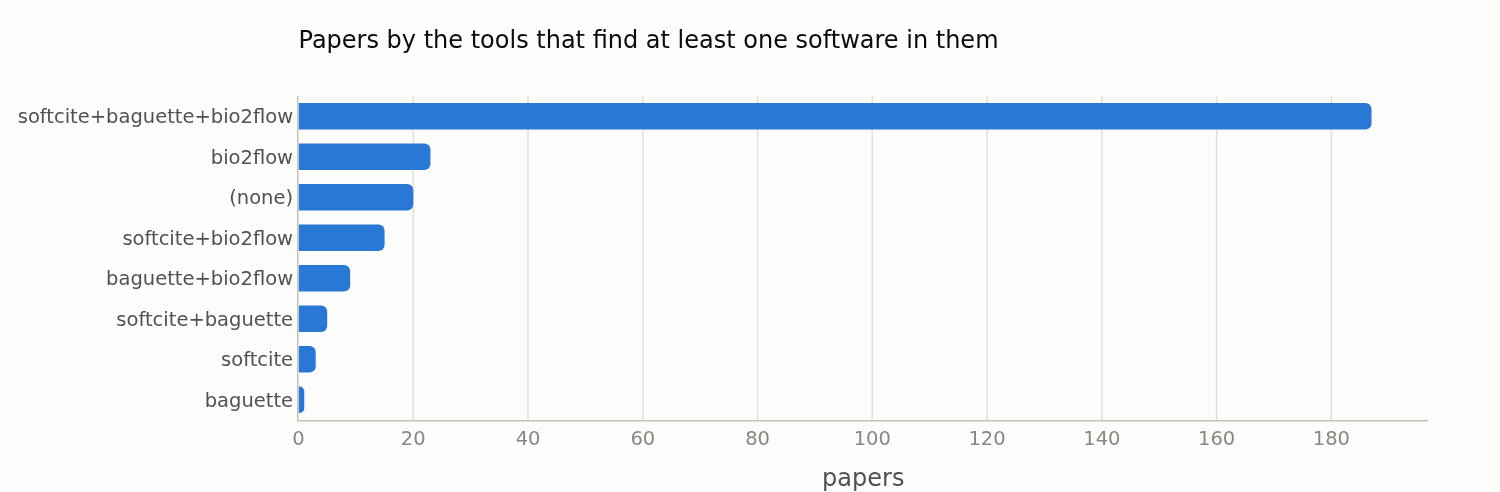

softcite+baguette+bio2flow    187
bio2flow                       23
(none)                         20
softcite+bio2flow              15
baguette+bio2flow               9
softcite+baguette               5
softcite                        3
baguette                        1
Name: count, dtype: int64

In [5]:
has_sw = pd.DataFrame({t: pd.Series({p: False for p in COMMON}) for t in TOOLS})
for t, g in found.groupby("tool"):
    has_sw.loc[g["paper"].unique(), t] = True
paper_pattern = has_sw.apply(lambda r: "+".join(t for t in TOOLS if r[t]) or "(none)", axis=1).value_counts()
hbar(paper_pattern, "Papers by the tools that find at least one software in them", "papers").show()
paper_pattern

In [6]:
# Papers where one tool finds nothing and another finds a lot.
n_per_paper = found.groupby(["paper", "tool"]).size().unstack("tool").reindex(index=sorted(COMMON), columns=TOOLS).fillna(0).astype(int)
lonely = n_per_paper[(n_per_paper == 0).any(axis=1) & (n_per_paper.max(axis=1) >= 5)].copy()
lonely["title"] = lonely.index.map(titles)
lonely.sort_values(TOOLS, ascending=False).head(15)

tool,softcite,baguette,bio2flow,title
paper,,,,
Variabilityinbrainimagingstudiesacrossdifferentanalysispipelines,12,0,1,HCP many pipeline
RepresentingbioinformaticsNextflowworkflowsinROCratechallengesandopportunities,5,5,0,Representing bioinformatics Nextflow workflows in RO-Crate : challenges and opportunities
Towardsreproducibleneuroimagingacrossdifferentanalysispipelines,5,0,0,Data Analysis Results Symposium Open large-scale collaborations to improve reproducibility
AphysiologydrivendeeplearningbasedpipelineforECGsegmentation,4,0,8,A physiology-driven deep learning-based pipeline for ECG segmentation
AssessingPerSampleMembershipInferenceVulnerabilitywithoutRetraining,4,0,7,Assessing Per-Sample Membership Inference Vulnerability without Retraining
RIGHTCOLLATERALSULCUSMORPHOLOGYCORRELATESWITHRECEPTIVECOMMUNICATIONINPRETERMBORNADOLESCENTSANDNEONATES,4,0,5,RIGHT COLLATERAL SULCUS MORPHOLOGY CORRELATES WITH RECEPTIVE COMMUNICATION IN PRETERM BORN ADOLESCENTS AND NEONATES
TighterPrivacyAuditingofDPSGDintheHiddenStateThreatModel,3,0,11,TIGHTER PRIVACY AUDITING OF DP-SGD IN THE HIDDEN STATE THREAT MODEL
LearningToSampleFromDiffusionModelsViaInverseReinforcementLearning,2,0,13,Learning To Sample From Diffusion Models Via Inverse Reinforcement Learning
FederatedCausalInferenceMultiStudyATEEstimationbeyondMetaAnalysis,2,0,10,Federated Causal Inference: Multi-Study ATE Estimation beyond Meta-Analysis


Per paper, the number of software each tool finds. Each dot is a paper; hover it for the title. Points on the diagonal are papers where the two tools find as many software (not necessarily the same ones).

softcite vs baguette: Spearman correlation of the counts per paper 0.85
softcite vs bio2flow: Spearman correlation of the counts per paper 0.67
baguette vs bio2flow: Spearman correlation of the counts per paper 0.59


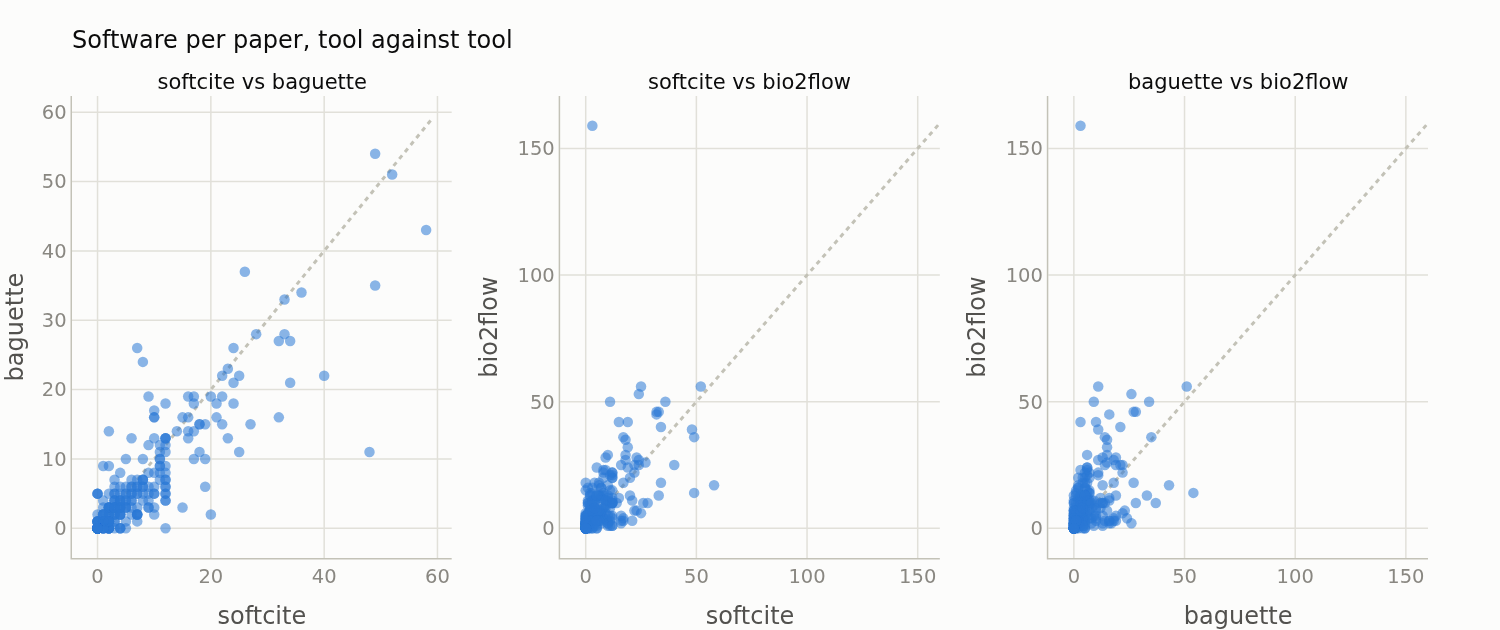

In [7]:
fig = make_subplots(rows=1, cols=3, subplot_titles=[f"{a} vs {b}" for a, b in combinations(TOOLS, 2)], horizontal_spacing=0.08)
for col, (a, b) in enumerate(combinations(TOOLS, 2), start=1):
    hi = int(n_per_paper[[a, b]].max().max()) + 1
    fig.add_trace(go.Scatter(x=[0, hi], y=[0, hi], mode="lines", line=dict(color=STYLE["axis"], dash="dot"),
                             hoverinfo="skip", showlegend=False), row=1, col=col)
    fig.add_trace(go.Scatter(
        x=n_per_paper[a], y=n_per_paper[b], mode="markers", showlegend=False,
        marker=dict(color=STYLE["series"][0], opacity=0.55, size=7),
        text=[(titles.get(p) or p)[:80] for p in n_per_paper.index],
        hovertemplate=f"%{{text}}<br>{a}: %{{x}}<br>{b}: %{{y}}<extra></extra>"), row=1, col=col)
    fig.update_xaxes(title_text=a, row=1, col=col)
    fig.update_yaxes(title_text=b, row=1, col=col)
    r = n_per_paper[a].rank().corr(n_per_paper[b].rank())  # Spearman, without scipy
    print(f"{a} vs {b}: Spearman correlation of the counts per paper {r:.2f}")
fig.update_annotations(font=dict(size=14, color=STYLE["ink"]))
fig.update_layout(title="Software per paper, tool against tool", height=420)
fig.show()

## 3 — Overlap of the software found

Two ways to say that two tools found the same software in a paper:

- **exact**: the same normalized name;
- **loose**: in the same paper, one name is the other, or its words appear in order inside the other (`spss` in `ibm spss statistics`, `deseq2` in `deseq2 r package`), or they are equal once a trailing version is dropped (`python 3.8` and `python`). Names of one character only match exactly. Names linked this way are grouped (connected components, per paper), and the group counts as one software.

Loose matching fixes most naming differences but can merge distinct software (`r` and `r cnn`); the exact figures are the lower bound.

In [8]:
VERSION_TAIL = re.compile(r"(\s+v?\d+[a-z0-9]*)+$")


def contains_words(short, long):
    """Whether the words of `short` appear, in order and contiguous, in `long`."""
    s, l = short.split(), long.split()
    return any(l[i:i + len(s)] == s for i in range(len(l) - len(s) + 1))


def loose_match(a, b):
    if a == b:
        return True
    if min(len(a), len(b)) < 2:
        return False
    if VERSION_TAIL.sub("", a) == VERSION_TAIL.sub("", b):
        return True
    short, long = sorted((a, b), key=len)
    return contains_words(short, long)


def group_names(names):
    """Connected components of the loose-match graph on one paper's names: {name: group id}."""
    names = sorted(names)
    parent = {n: n for n in names}

    def root(n):
        while parent[n] != n:
            parent[n] = parent[parent[n]]
            n = parent[n]
        return n

    for a, b in combinations(names, 2):
        if loose_match(a, b):
            parent[root(a)] = root(b)
    return {n: root(n) for n in names}


found["exact_key"] = found["name"]
found["loose_key"] = ""
for paper, idx in found.groupby("paper").groups.items():
    groups = group_names(found.loc[idx, "name"].unique())
    found.loc[idx, "loose_key"] = found.loc[idx, "name"].map(groups)


def entities(level):
    """One row per software of a paper (at `level` exact or loose), with the tools that found it."""
    key = f"{level}_key"
    ent = (found.groupby(["paper", key])
           .agg(tools=("tool", lambda s: frozenset(s)), names=("name", lambda s: sorted(set(s))))
           .reset_index().rename(columns={key: "key"}))
    ent["region"] = ent["tools"].map(lambda ts: "+".join(t for t in TOOLS if t in ts))
    for t in TOOLS:
        ent[t] = ent["tools"].map(lambda ts, t=t: t in ts)
    return ent


ENT = {level: entities(level) for level in ("exact", "loose")}
REGIONS = ["softcite", "baguette", "bio2flow", "softcite+baguette", "softcite+bio2flow", "baguette+bio2flow", "softcite+baguette+bio2flow"]
regions = pd.DataFrame({level: e["region"].value_counts() for level, e in ENT.items()}).reindex(REGIONS).fillna(0).astype(int)
regions.loc["total"] = regions.sum()
regions

,exact,loose
region,,
softcite,815,562
baguette,781,556
bio2flow,1688,1493
softcite+baguette,397,400
softcite+bio2flow,469,438
baguette+bio2flow,147,133
softcite+baguette+bio2flow,458,501
total,4755,4083


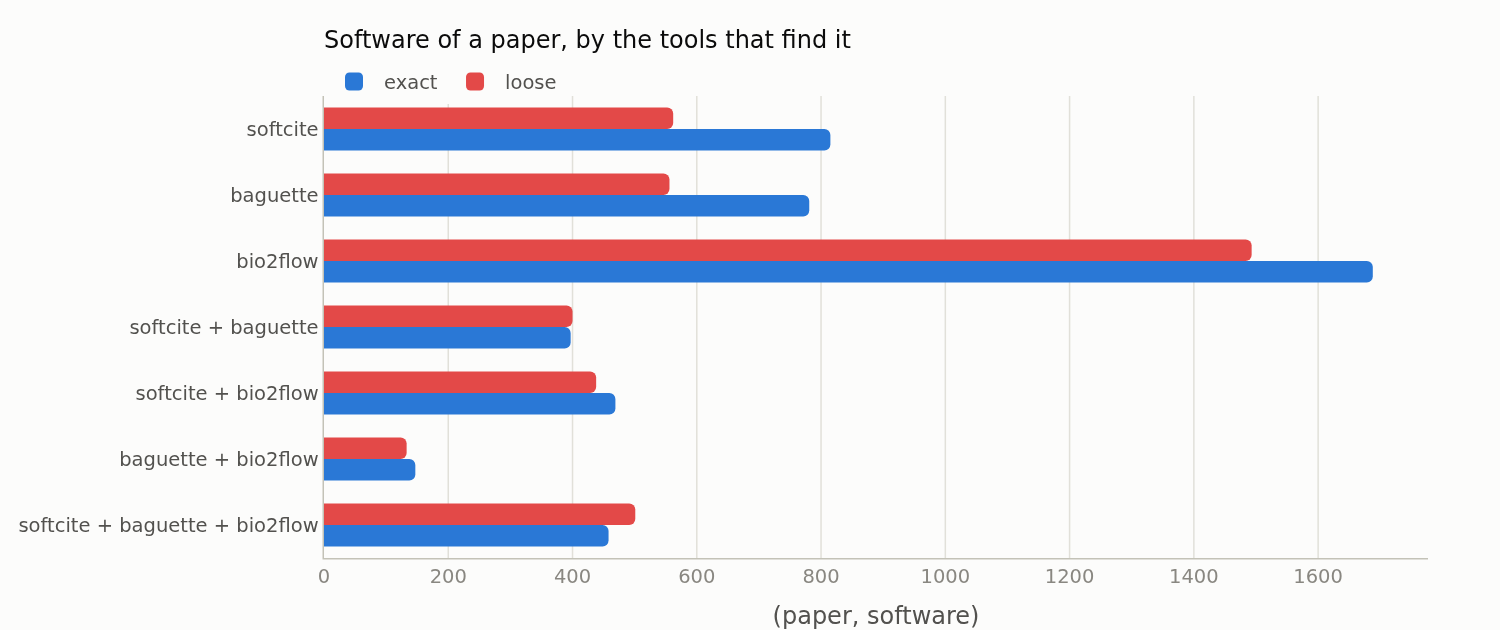

In [9]:
fig = go.Figure()
for k, level in enumerate(("exact", "loose")):
    v = regions.loc[REGIONS, level]
    fig.add_trace(go.Bar(name=level, x=v.values[::-1], y=[r.replace("+", " + ") for r in REGIONS[::-1]], orientation="h",
                         marker_color=STYLE["series"][k + 6 if k else 0],
                         hovertemplate=f"<b>%{{y}}</b><br>{level}: %{{x:,d}} software<extra></extra>"))
fig.update_layout(title="Software of a paper, by the tools that find it", xaxis_title="(paper, software)", barmode="group",
                  height=420, legend=dict(orientation="h", y=1.08, x=0))
fig.update_yaxes(showgrid=False, tickfont=dict(color=STYLE["ink2"]))
fig.show()

**Most software is found by one tool only.** Even with loose matching, only a small share of the (paper, software) pairs is found by the three tools. The rest of the notebook asks what the tool-specific finds are.

### Pairwise agreement

For a pair of tools A and B, *coverage of A by B* is the share of A's software that B also finds (the recall of B if A were the gold standard). Asymmetric: the matrix reads row = reference, column = the tool that is checked. The Jaccard index is the shared software over the software of either.

exact: Jaccard
          softcite  baguette  bio2flow
softcite      1.00      0.28      0.23
baguette      0.28      1.00      0.15
bio2flow      0.23      0.15      1.00

loose: Jaccard
          softcite  baguette  bio2flow
softcite      1.00      0.35      0.27
baguette      0.35      1.00      0.18
bio2flow      0.27      0.18      1.00



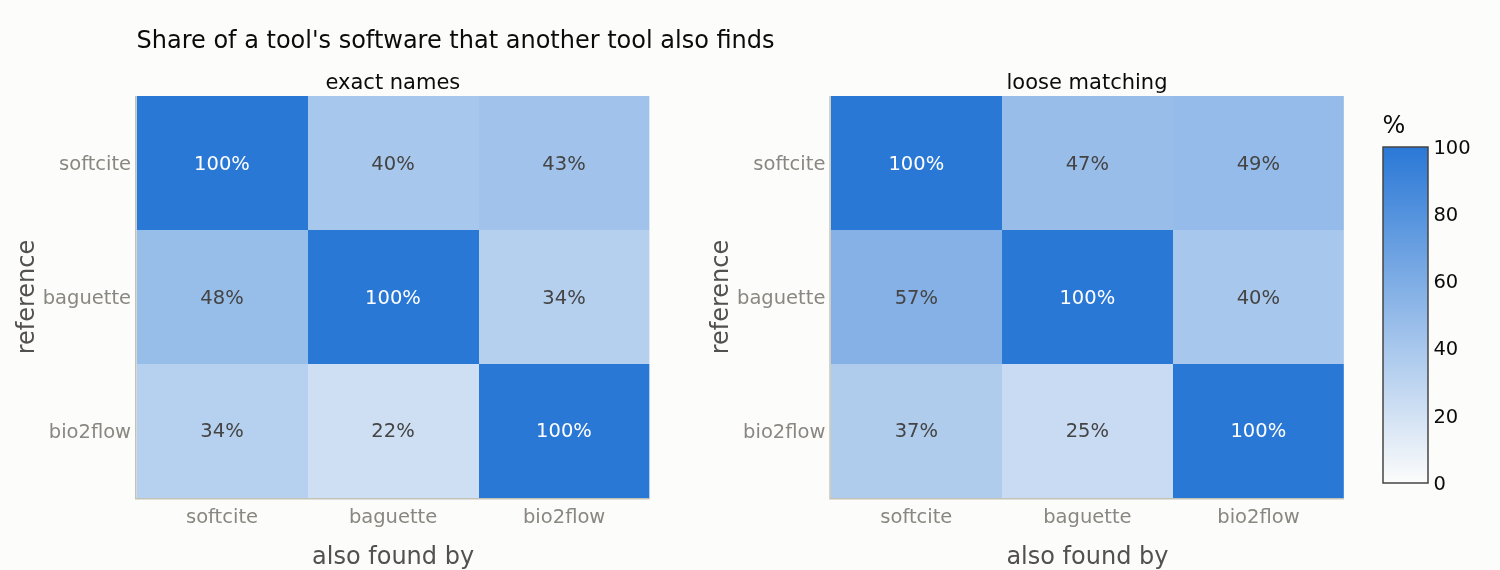

In [10]:
def pairwise(ent):
    cov = pd.DataFrame(index=TOOLS, columns=TOOLS, dtype=float)
    jac = pd.DataFrame(index=TOOLS, columns=TOOLS, dtype=float)
    for a in TOOLS:
        for b in TOOLS:
            both = (ent[a] & ent[b]).sum()
            cov.loc[a, b] = both / ent[a].sum()
            jac.loc[a, b] = both / (ent[a] | ent[b]).sum()
    return cov, jac


fig = make_subplots(rows=1, cols=2, subplot_titles=("exact names", "loose matching"), horizontal_spacing=0.15)
for col, level in enumerate(("exact", "loose"), start=1):
    cov, jac = pairwise(ENT[level])
    fig.add_trace(go.Heatmap(
        z=cov.values * 100, x=TOOLS, y=TOOLS, zmin=0, zmax=100, showscale=col == 2,
        colorscale=[[0, STYLE["surface"]], [1, STYLE["series"][0]]], colorbar=dict(title="%"),
        text=[[f"{v:.0f}%" for v in row] for row in cov.values * 100], texttemplate="%{text}",
        hovertemplate="%{x} finds %{z:.1f}% of the software %{y} finds<extra></extra>"), row=1, col=col)
    print(f"{level}: Jaccard\n{jac.round(2).to_string()}\n")
fig.update_yaxes(autorange="reversed", title_text="reference", showgrid=False)
fig.update_xaxes(title_text="also found by", showgrid=False)
fig.update_annotations(font=dict(size=14, color=STYLE["ink"]))
fig.update_layout(title="Share of a tool's software that another tool also finds", height=380)
fig.show()

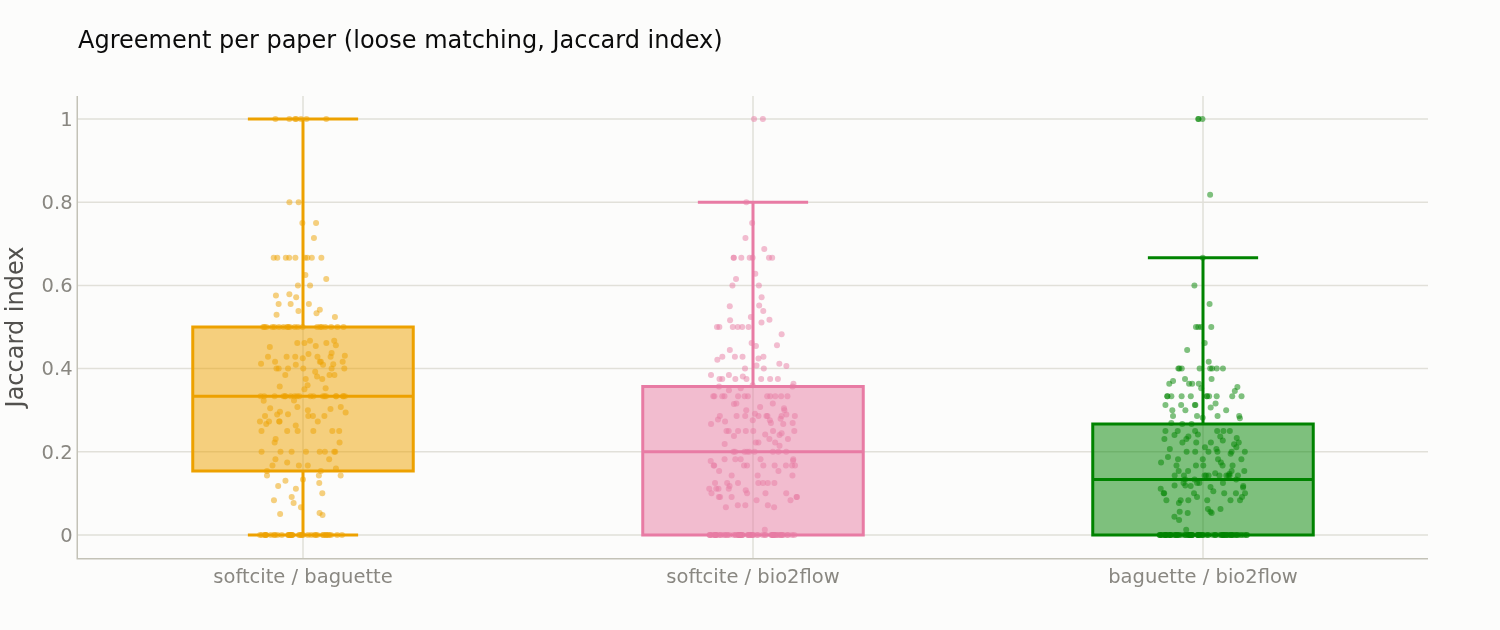

,count,mean,std,min,25%,50%,75%,max
pair,,,,,,,,
baguette / bio2flow,240.0,0.16,0.18,0.0,0.00,0.13,0.27,1.0
softcite / baguette,220.0,0.33,0.24,0.0,0.15,0.33,0.50,1.0
softcite / bio2flow,242.0,0.23,0.21,0.0,0.00,0.20,0.36,1.0


In [11]:
# Per paper: the Jaccard index of each pair (papers where at least one of the two finds something).
per_paper = []
ent = ENT["loose"]
for paper, g in ent.groupby("paper"):
    for a, b in combinations(TOOLS, 2):
        union = (g[a] | g[b]).sum()
        if union:
            per_paper.append({"paper": paper, "pair": f"{a} / {b}", "jaccard": (g[a] & g[b]).sum() / union, "union": union})
per_paper = pd.DataFrame(per_paper)

fig = go.Figure()
for k, (pair, g) in enumerate(per_paper.groupby("pair", sort=False)):
    fig.add_trace(go.Box(y=g["jaccard"], name=pair, boxpoints="all", jitter=0.4, pointpos=0, marker=dict(size=4, opacity=0.5),
                         line=dict(color=STYLE["series"][k + 3]), text=[(titles.get(p) or p)[:80] for p in g["paper"]],
                         hovertemplate="%{text}<br>Jaccard %{y:.2f}<extra></extra>"))
fig.update_layout(title="Agreement per paper (loose matching, Jaccard index)", yaxis_title="Jaccard index", height=420, showlegend=False)
fig.show()
per_paper.groupby("pair")["jaccard"].describe().round(2)

## 4 — What the three tools agree on, and what each one finds alone

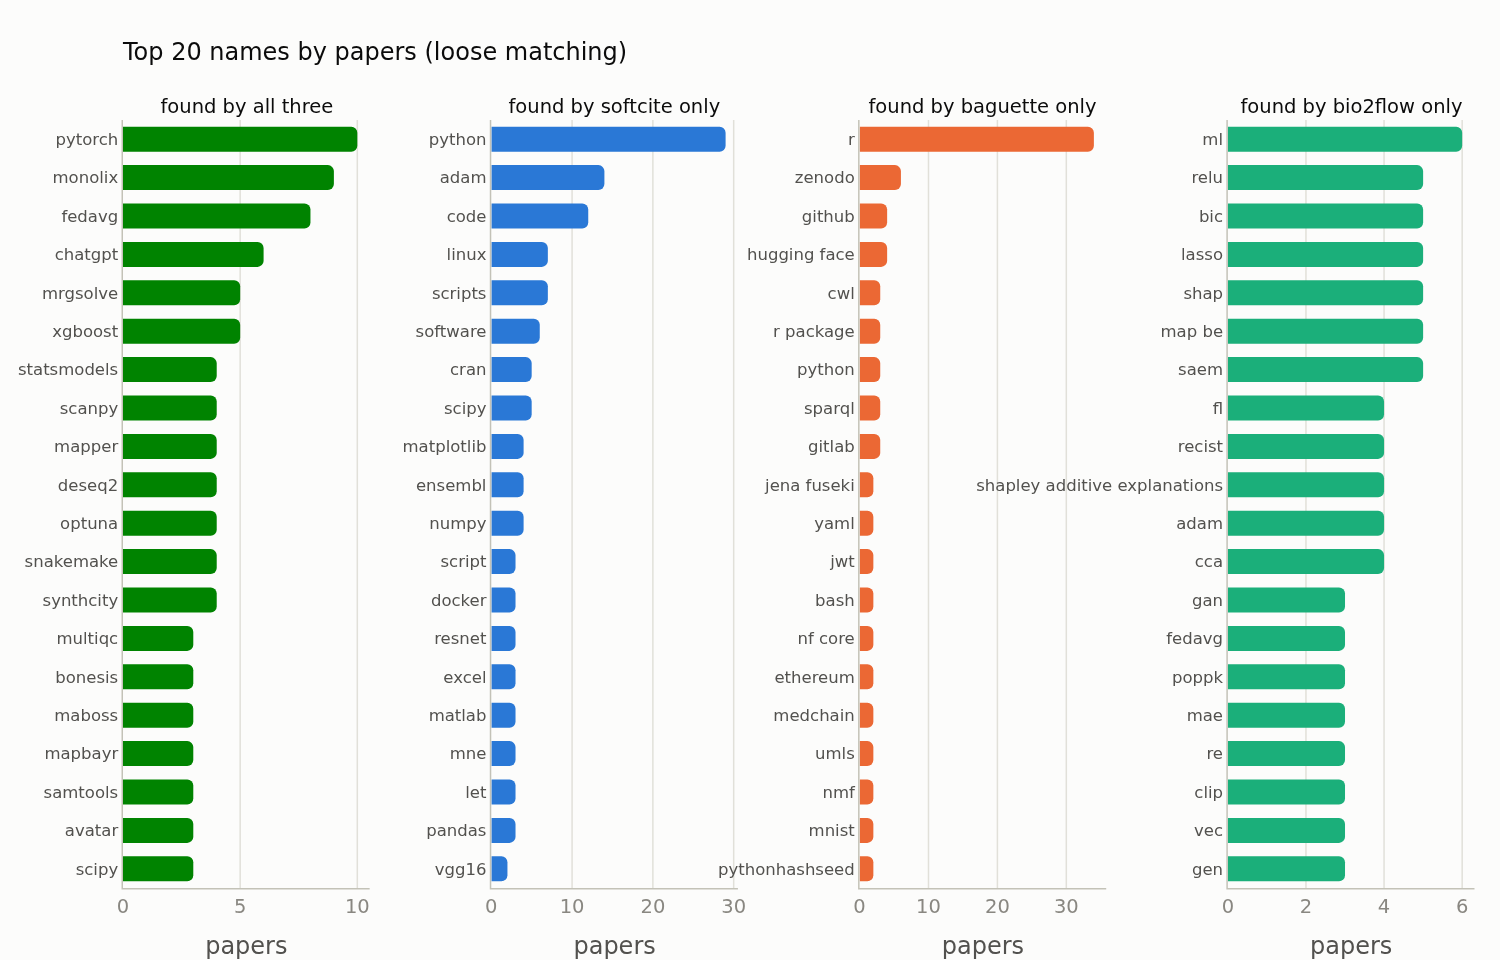

In [12]:
TOP = 20


def top_names(ent, region, n=TOP):
    """The names in a region, by papers (the most frequent spelling of each loose group)."""
    sub = ent[ent["region"] == region]
    label = sub["names"].map(lambda ns: min(ns, key=len))
    return label.value_counts().head(n)


fig = make_subplots(rows=1, cols=4, horizontal_spacing=0.09,
                    subplot_titles=["found by all three"] + [f"found by {t} only" for t in TOOLS])
for col, region in enumerate(["softcite+baguette+bio2flow"] + TOOLS, start=1):
    v = top_names(ENT["loose"], region)[::-1]
    color = STYLE["series"][2 + 3] if col == 1 else COLOR[TOOLS[col - 2]]
    fig.add_trace(go.Bar(x=v.values, y=v.index, orientation="h", marker_color=color, showlegend=False,
                         hovertemplate="<b>%{y}</b><br>%{x} papers<extra></extra>"), row=1, col=col)
fig.update_yaxes(showgrid=False, tickfont=dict(color=STYLE["ink2"], size=11))
fig.update_xaxes(title_text="papers")
fig.update_annotations(font=dict(size=13, color=STYLE["ink"]))
fig.update_layout(title=f"Top {TOP} names by papers (loose matching)", height=640, margin=dict(l=16, r=16, t=80, b=48))
fig.show()

Things to look for in these lists:

- **Consensus** software are mostly specific, well-known packages (PyTorch, XGBoost, Scanpy, samtools…).
- **Softcite alone** finds programming languages (`python`) and libraries the others skip, but also generic words tagged as explicit software (`code`, `scripts`, `software`, `tool`) and model or optimizer names (`adam`, `resnet`).
- **Baguette alone** finds `R` in many papers where the others don't, and code and data platforms (`zenodo`, `github`, `hugging face`).
- **bio2flow alone** finds methods and their acronyms (`lasso`, `gan`, `shap`, `bic`, `relu`): CoPaLink's `Tool` class was trained on bioinformatics workflows, where methods and tools are close.

### The shape of the names

Simple surface features of the names in each region: an acronym (all capitals, as written), a name with a digit, a single word, a lowercase common word, the name length. Computed on the raw form of the first tool that found it.

In [13]:
raw_of = found.groupby(["paper", "loose_key"])["raw"].first()
ent = ENT["loose"].copy()
ent["raw"] = [raw_of[(p, k)] for p, k in zip(ent["paper"], ent["key"])]
ent["acronym"] = ent["raw"].str.fullmatch(r"[A-Z][A-Z0-9\-]{1,}")
ent["has_digit"] = ent["raw"].str.contains(r"\d")
ent["one_word"] = ~ent["raw"].str.strip().str.contains(r"\s")
ent["lowercase_word"] = ent["raw"].str.fullmatch(r"[a-z]+")
ent["length"] = ent["raw"].str.len()

shape = ent.groupby("region")[["acronym", "has_digit", "one_word", "lowercase_word"]].mean().mul(100).round(1)
shape["median length"] = ent.groupby("region")["length"].median()
shape["software"] = ent["region"].value_counts()
shape.reindex(REGIONS)

,acronym,has_digit,one_word,lowercase_word,median length,software
region,,,,,,
softcite,12.8,4.8,88.4,24.6,7.0,562
baguette,21.9,12.1,75.9,7.0,8.0,556
bio2flow,52.5,14.8,94.4,8.0,5.0,1493
softcite+baguette,13.2,5.0,88.5,11.2,7.0,400
softcite+bio2flow,24.7,5.3,98.9,13.9,7.0,438
baguette+bio2flow,35.3,11.3,90.2,5.3,6.0,133
softcite+baguette+bio2flow,18.4,6.0,94.0,12.2,7.0,501


### Is a software found by several tools mentioned more often?

A software named many times in a paper should be easier to catch. Using Softcite's mention count for the software it finds: the share also found by Baguette, by bio2flow, by both.

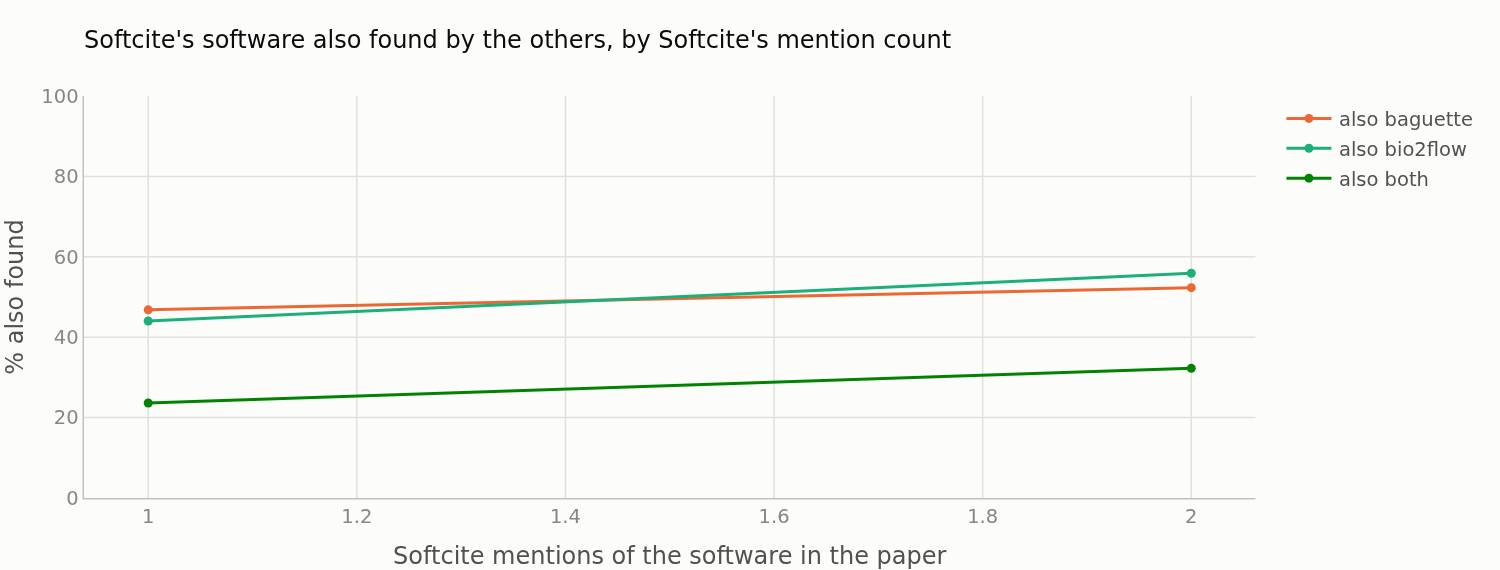

,software,also baguette,also bio2flow,also both
mentions in the paper,,,,
1,1113,0.468,0.440,0.236
2,279,0.523,0.559,0.323
3–4,249,0.538,0.510,0.309
5–9,202,0.604,0.604,0.366
10+,296,0.608,0.618,0.392


In [14]:
sc = found[found["tool"] == "softcite"].merge(ENT["loose"][["paper", "key"] + TOOLS], left_on=["paper", "loose_key"], right_on=["paper", "key"])
bins = [0, 1, 2, 4, 9, 10_000]
labels = ["1", "2", "3–4", "5–9", "10+"]
sc["mentions in the paper"] = pd.cut(sc["n_mentions"], bins=bins, labels=labels)
by_freq = sc.groupby("mentions in the paper", observed=False).agg(
    software=("name", "size"),
    **{f"also {t}": (t, "mean") for t in ("baguette", "bio2flow")},
    **{"also both": ("baguette", lambda s: (s & sc.loc[s.index, "bio2flow"]).mean())})

fig = go.Figure()
for k, col in enumerate(["also baguette", "also bio2flow", "also both"]):
    fig.add_trace(go.Scatter(x=labels, y=by_freq[col] * 100, mode="lines+markers", name=col,
                             marker_color=[COLOR["baguette"], COLOR["bio2flow"], STYLE["series"][5]][k],
                             customdata=by_freq["software"], hovertemplate=f"{col}: %{{y:.1f}}%<br>%{{customdata}} Softcite software<extra></extra>"))
fig.update_layout(title="Softcite's software also found by the others, by Softcite's mention count", height=380,
                  xaxis_title="Softcite mentions of the software in the paper", yaxis_title="% also found", yaxis_range=[0, 100])
fig.show()
by_freq.round(3)

### Softcite's software types

Softcite separates `software`, `component` (plugins, packages) and `environment` (programming languages). Which of them do the others miss?

In [15]:
by_type = sc.groupby("software_type").agg(software=("name", "size"), **{f"also {t} (%)": (t, "mean") for t in ("baguette", "bio2flow")})
by_type[[c for c in by_type if c.endswith("(%)")]] *= 100
by_type.round(1)

,software,also baguette (%),also bio2flow (%)
software_type,,,
component,136,63.2,50.7
environment,80,53.8,18.8
software,1923,50.7,51.7


### Software that Baguette files as a dataset

Baguette extracts datasets too. Some names other tools call software are among Baguette's **datasets** for the same paper: a type disagreement, not a miss.

In [16]:
bag_datasets = all_mentions[(all_mentions["tool"] == "baguette") & (all_mentions["type"] == "dataset") & all_mentions["name"].ne("")]
bag_ds_keys = set(zip(bag_datasets["paper"], bag_datasets["name"]))
not_bag = ENT["loose"][~ENT["loose"]["baguette"]].copy()
not_bag["baguette dataset"] = [any((p, n) in bag_ds_keys for n in ns) for p, ns in zip(not_bag["paper"], not_bag["names"])]
print(f"Of the {len(not_bag):,} software Baguette doesn't find as software, {not_bag['baguette dataset'].sum():,} "
      f"({not_bag['baguette dataset'].mean():.1%}) are among its datasets for the paper.")
print("\nMost frequent ones (papers):")
print(not_bag[not_bag["baguette dataset"]]["names"].map(lambda ns: min(ns, key=len)).value_counts().head(15).to_string())

Of the 2,493 software Baguette doesn't find as software, 196 (7.9%) are among its datasets for the paper.

Most frequent ones (papers):
names
imagenet       3
nilearn        2
star           2
dinov2         2
cellphonedb    2
nupack         2
gencode        2
scibert        2
uniprot        2
ffhq           2
share          2
abc            2
chat           2
mass           2
brainmap       2


### Purpose: Softcite against Baguette

Both tools say whether the paper **used** or **created** a software. Softcite judges it over the whole paper (`documentContextAttributes`); Baguette gives one role per software (`reused` → used, `produced` → created, `mentioned` → neither). On the software both find (loose matching):

In [17]:
def purpose_label(used, created):
    return "used + created" if used and created else "created" if created else "used" if used else "neither"


pp = (found[found["tool"].isin(["softcite", "baguette"])]
      .groupby(["paper", "loose_key", "tool"])[["used", "created"]].max().unstack("tool").dropna())
pp_s = [purpose_label(u, c) for u, c in zip(pp[("used", "softcite")], pp[("created", "softcite")])]
pp_b = [purpose_label(u, c) for u, c in zip(pp[("used", "baguette")], pp[("created", "baguette")])]
order = ["used", "created", "used + created", "neither"]
purpose_xt = pd.crosstab(pd.Series(pp_s, name="Softcite"), pd.Series(pp_b, name="Baguette")).reindex(index=order, columns=order).fillna(0).astype(int)
agree = sum(purpose_xt.loc[o, o] for o in order) / purpose_xt.values.sum()
print(f"{purpose_xt.values.sum():,} software found by both; same purpose for {agree:.1%}")
purpose_xt

901 software found by both; same purpose for 62.4%


Baguette,used,created,used + created,neither
Softcite,,,,
used,424,4,1,50
created,24,6,1,30
used + created,104,23,9,42
neither,58,2,0,123


## 5 — Papers where the tools disagree most

Papers with the most software found by one tool only (loose matching). A good place to start reading the papers.

In [18]:
ent = ENT["loose"]
disagree = ent.groupby("paper").agg(
    software=("key", "size"),
    all_three=("region", lambda s: (s == "softcite+baguette+bio2flow").sum()),
    **{f"only {t}": ("region", lambda s, t=t: (s == t).sum()) for t in TOOLS})
disagree["single-tool share"] = (disagree[[f"only {t}" for t in TOOLS]].sum(axis=1) / disagree["software"]).round(2)
disagree["title"] = disagree.index.map(lambda p: (titles.get(p) or p)[:90])
disagree[disagree["software"] >= 8].sort_values("single-tool share", ascending=False).head(15)

,software,all_three,only softcite,only baguette,only bio2flow,single-tool share,title
paper,,,,,,,
ABlockchainEnhancedReversibleWatermarkingFrameworkforEndtoEndDataTraceabilityinFederatedLearningSystems,11,0,4,4,3,1.00,A Blockchain-Enhanced Reversible Watermarking Framework for End-to-End Data Traceability i
PerformanceevaluationofpredictiveAImodelstosupportmedicaldecisionsOverviewandguidance,15,0,0,1,14,1.00,Performance evaluation of predictive AI models to support medical decisions: Overview and
Evaluationofperformancemeasuresinpredictiveartificialintelligencemodelstosupportmedicaldecisionsoverviewandguidance,14,0,1,3,10,1.00,Evaluation of performance measures in predictive artificial intelligence models to support
RISETwoStageRankBasedIdentificationofHighDimensionalSurrogateMarkersAppliedtoVaccinology,161,1,1,1,156,0.98,RISE: Two‐Stage Rank‐Based Identification of High‐Dimensional Surrogate Markers Applied to
AWhiteBoxWatermarkingModulationforEncryptedDNNinHomomorphicFederatedLearning,18,0,0,1,16,0.94,AWhiteBoxWatermarkingModulationforEncryptedDNNinHomomorphicFederatedLearning
LearningToSampleFromDiffusionModelsViaInverseReinforcementLearning,14,0,1,0,12,0.93,Learning To Sample From Diffusion Models Via Inverse Reinforcement Learning
MechanisticlearningtopredictresponseandsurvivalinimmunooncologyAmodelingjourneyinimmunooncology,33,1,5,5,20,0.91,MechanisticlearningtopredictresponseandsurvivalinimmunooncologyAmodelingjourneyinimmunoonc
Lareconnaissanceautomatiquedephonmesestellerellementadaptepourlanalysedelaparolespontane,10,0,0,0,9,0.90,La reconnaissance automatique de phonèmes est-elle réellement adaptée pour l'analyse de la
MechanisticLearningforSurvivalPredictioninNSCLCUsingRoutineBloodBiomarkersandTumorKinetics,10,1,0,0,9,0.90,Mechanistic Learning for Survival Prediction in NSCLC Using Routine Blood Biomarkers and T


In [19]:
# Look at one paper: every software, the tools that found it, and a context.
PAPER = disagree[disagree["software"] >= 8].sort_values("single-tool share", ascending=False).index[0]
print(titles.get(PAPER) or PAPER, "\n")
view = ent[ent["paper"] == PAPER].sort_values("region")
for _, r in view.iterrows():
    print(f"{r['region']:28s} {' / '.join(r['names'])}")

A Blockchain-Enhanced Reversible Watermarking Framework for End-to-End Data Traceability in Federated Learning Systems 

baguette                     githubfoot 0
baguette                     paroma med
baguette                     peng et al 26
baguette                     zheng et al 27
bio2flow                     append
bio2flow                     cat
bio2flow                     sha256
softcite                     adam
softcite                     alg
softcite                     vgg 16
softcite                     vgg16 / vgg16 2


## 6 — Mentions that are not explicit software

The comparison above leaves out what a tool doesn't call explicit software. For completeness:

In [20]:
other = all_mentions[~is_explicit]
other.groupby(["tool", "type", "software_type"]).size().rename("mentions").to_frame()

mentions
tool     type     software_type          
baguette dataset  implicit           2049
                  software           2204
         software implicit            297
softcite software implicit            292

In [21]:
for tool, label in (("softcite", "implicit"), ("baguette", "implicit")):
    sub = other[(other["tool"] == tool) & (other["type"] == "software") & (other["software_type"] == label)]
    print(f"{tool} implicit software, top forms (papers):")
    print(sub.groupby("name")["paper"].nunique().sort_values(ascending=False).head(10).to_string(), "\n")

softcite implicit software, top forms (papers):
name
code        97
scripts     28
script      13
tool         8
codes        7
library      7
tools        4
module       3
package      3
software     2 

baguette implicit software, top forms (papers):
name
code              18
online version     9
framework          6
llm                4
prototype          4
python library     4
tool               3
platform           3
model              3
package            3 



## 7 — The judge sample

Without gold annotations, we ask a cheap LLM judge (Claude Haiku) to label a **sample of the software of each region**: the one-tool regions (where the tools disagree), the two-tool regions, and the consensus as a control. For each item the judge sees the name and up to one context per tool that found it (the mention's sentence for Softcite and bio2flow, Baguette's evidence), and returns:

- `category`: `software` (a named program, library, package, tool, platform you run), `programming_language`, `ml_model` (a trained model or architecture: ResNet, BERT, GPT-4), `database`, `platform_service` (GitHub, Zenodo, a web service you don't run), `dataset`, `method` (an algorithm, statistical method, metric), `generic` (code, scripts, tool), `other`;
- `is_software`: whether it is a named software in the Softcite sense (software, component or programming language: `software` and `programming_language`);
- a confidence and a short reason.

The cell below writes the sample to `notebooks/extractor_judge/candidates.jsonl` (fixed seed: rerunning it gives the same sample). The judgments are in `judgments.jsonl` next to it; section 8 reads them.

In [22]:
SAMPLE = {r: 60 for r in TOOLS} | {r: 25 for r in REGIONS[3:6]} | {REGIONS[6]: 30}
SEED = 2026

ctx_of = found.set_index(["tool", "paper", "name"])["context"]
raw_of_tool = found.set_index(["tool", "paper", "name"])["raw"]


def around(text, name, n=420):
    """At most n characters of the context, centred on the first occurrence of the name."""
    text = re.sub(r"\s+", " ", text or "").strip()
    if len(text) <= n:
        return text
    at = max(text.find(name), 0)
    start = max(0, min(at - n // 2, len(text) - n))
    return ("…" if start else "") + text[start:start + n].strip() + ("…" if start + n < len(text) else "")


def contexts(paper, names, tools):
    """Up to one context per tool that found the software, preferring the shortest name's context."""
    out = {}
    for t in TOOLS:
        if t not in tools:
            continue
        for n in sorted(names, key=len):
            if (t, paper, n) in ctx_of.index:
                raw = raw_of_tool[(t, paper, n)]
                out[t] = {"name": raw, "context": around(ctx_of[(t, paper, n)], raw)}
                break
    return out


cands = []
for region, n in SAMPLE.items():
    sub = ENT["loose"][ENT["loose"]["region"] == region]
    for _, r in sub.sample(min(n, len(sub)), random_state=SEED).iterrows():
        cands.append({"paper": r["paper"], "region": region, "names": r["names"],
                      "contexts": contexts(r["paper"], r["names"], r["tools"])})
# Shuffle so the judge doesn't see the regions in order, and hide the region from it.
cands = pd.DataFrame(cands).sample(frac=1, random_state=SEED).reset_index(drop=True)
cands.insert(0, "id", [f"c{i:03d}" for i in range(len(cands))])

JUDGE_DIR.mkdir(parents=True, exist_ok=True)
with open(JUDGE_DIR / "candidates.jsonl", "w", encoding="utf-8") as fh:
    for r in cands.to_dict("records"):
        fh.write(json.dumps(r, ensure_ascii=False) + "\n")
with open(JUDGE_DIR / "items.jsonl", "w", encoding="utf-8") as fh:  # what the judge sees: no region, no tool names
    for r in cands.to_dict("records"):
        fh.write(json.dumps({"id": r["id"], "name": min(r["names"], key=len),
                             "contexts": [c["context"] for c in r["contexts"].values()]}, ensure_ascii=False) + "\n")
print(f"{len(cands)} candidates written to {JUDGE_DIR}")
cands["region"].value_counts().reindex(REGIONS)

285 candidates written to ../notebooks/extractor_judge


region
softcite                      60
baguette                      60
bio2flow                      60
softcite+baguette             25
softcite+bio2flow             25
baguette+bio2flow             25
softcite+baguette+bio2flow    30
Name: count, dtype: int64

## 8 — What the judge says

Share of the sampled software the judge calls a real software (`is_software`), per region, with a 95% Wilson interval. A one-tool region with a high share holds real software the other tools miss; a low share means that tool's extra finds are mostly noise.

In [23]:
JUDGMENTS = JUDGE_DIR / "judgments.jsonl"
if not JUDGMENTS.exists():
    print(f"No {JUDGMENTS} yet: run the judge on items.jsonl (see notebooks/extractor_judge/README.md).")
else:
    judg = pd.read_json(JUDGMENTS, lines=True)
    judged = cands.merge(judg, on="id", how="inner")
    print(f"{len(judged)} of {len(cands)} candidates judged")


def wilson(k, n, z=1.96):
    if n == 0:
        return float("nan"), float("nan")
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

285 of 285 candidates judged


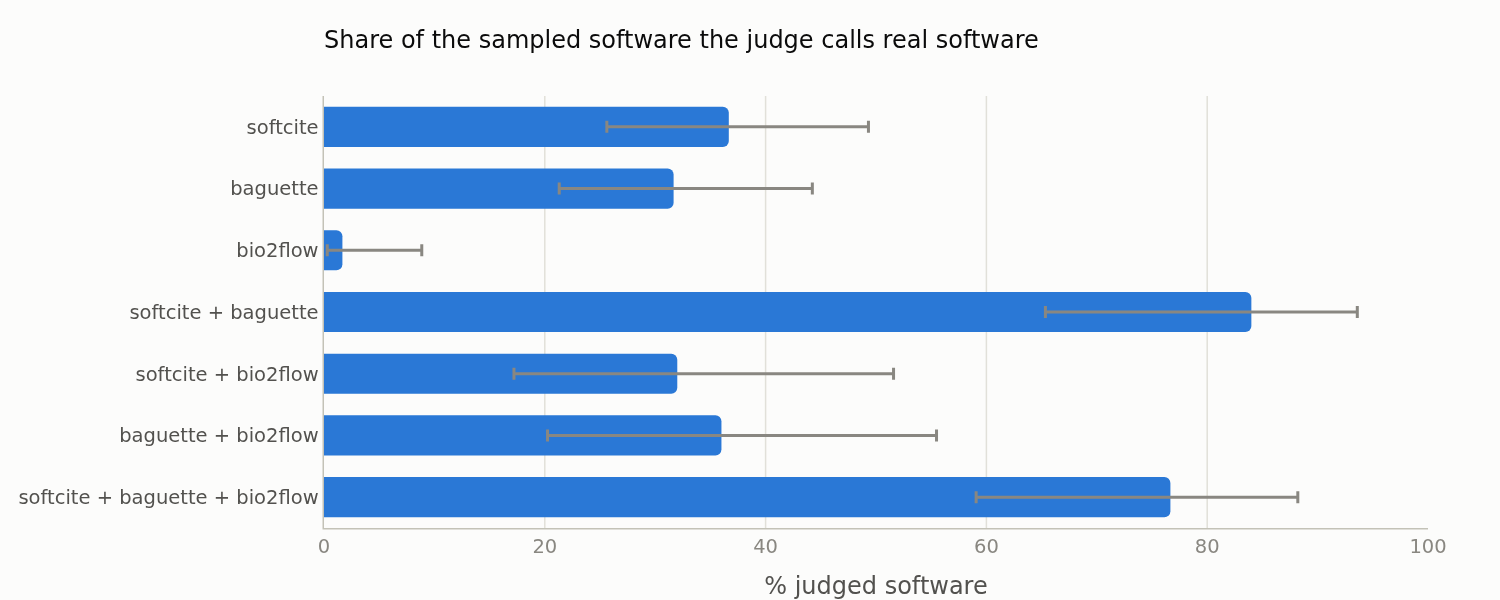

,judged,software,share,low,high
region,,,,,
softcite,60,22,0.37,0.26,0.49
baguette,60,19,0.32,0.21,0.44
bio2flow,60,1,0.02,0.00,0.09
softcite+baguette,25,21,0.84,0.65,0.94
softcite+bio2flow,25,8,0.32,0.17,0.52
baguette+bio2flow,25,9,0.36,0.20,0.55
softcite+baguette+bio2flow,30,23,0.77,0.59,0.88


In [24]:
if JUDGMENTS.exists():
    rows = []
    for region in REGIONS:
        g = judged[judged["region"] == region]
        k, n = int(g["is_software"].sum()), len(g)
        lo, hi = wilson(k, n)
        rows.append({"region": region, "judged": n, "software": k, "share": k / n if n else float("nan"), "low": lo, "high": hi})
    judge_share = pd.DataFrame(rows).set_index("region")

    fig = go.Figure(go.Bar(
        x=judge_share["share"][::-1] * 100, y=[r.replace("+", " + ") for r in REGIONS[::-1]], orientation="h",
        marker_color=STYLE["series"][0],
        error_x=dict(type="data", symmetric=False, color=STYLE["muted"],
                     array=(judge_share["high"] - judge_share["share"])[::-1] * 100,
                     arrayminus=(judge_share["share"] - judge_share["low"])[::-1] * 100),
        customdata=judge_share[["software", "judged"]][::-1].values,
        hovertemplate="<b>%{y}</b><br>%{x:.0f}% software (%{customdata[0]} of %{customdata[1]})<extra></extra>"))
    fig.update_layout(title="Share of the sampled software the judge calls real software", xaxis_title="% judged software",
                      xaxis_range=[0, 100], height=400)
    fig.update_yaxes(showgrid=False, tickfont=dict(color=STYLE["ink2"]))
    fig.show()
    display(judge_share.round(2))

In this run, the software found by Softcite and Baguette together (with or without bio2flow) is mostly real. The single-tool finds of Softcite and Baguette are about one third real software: each misses software the other one finds. bio2flow's single-tool finds are almost never software. Adding bio2flow to a pair barely changes the share, but software found by bio2flow and only one other tool is about one third real.

### What the rest is

The judge's category for the sampled items of each region: what a tool finds that is not software.

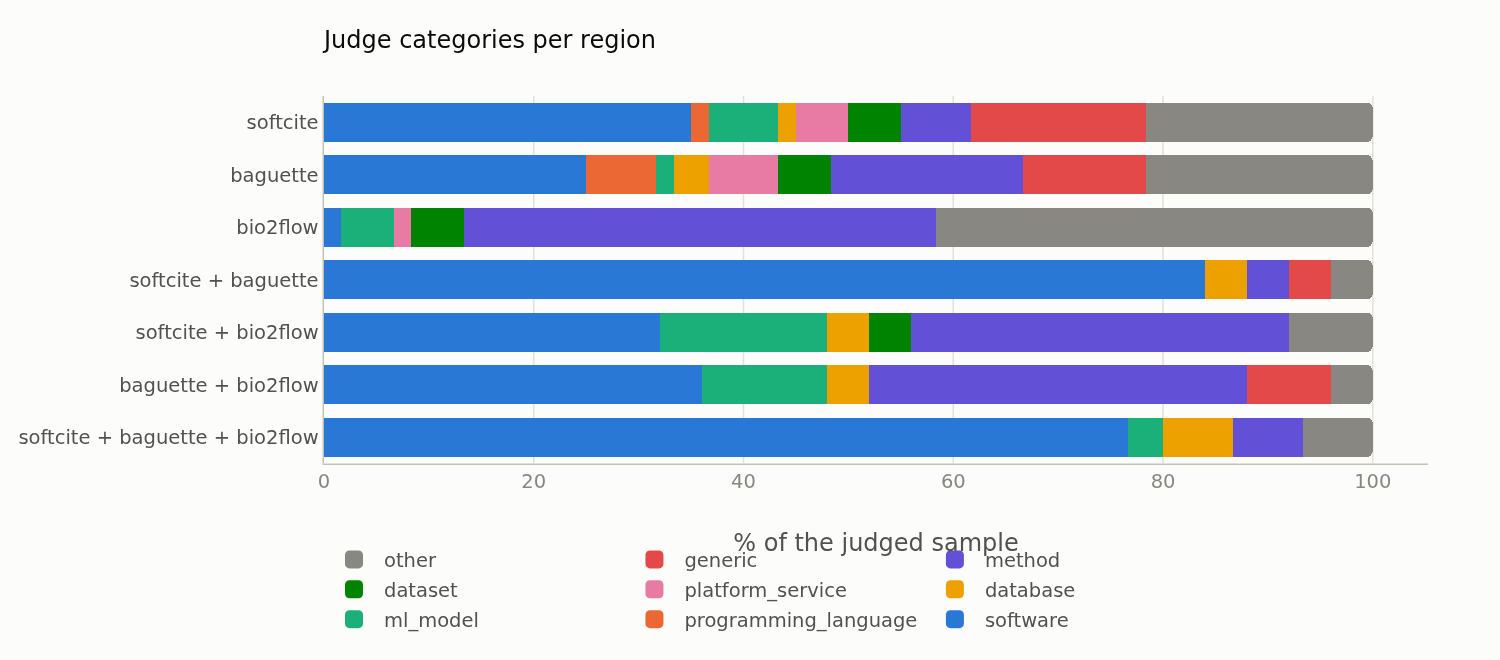

category,software,programming_language,ml_model,database,platform_service,dataset,method,generic,other
region,,,,,,,,,
softcite,35,2,7,2,5,5,7,17,22
baguette,25,7,2,3,7,5,18,12,22
bio2flow,2,0,5,0,2,5,45,0,42
softcite+baguette,84,0,0,4,0,0,4,4,4
softcite+bio2flow,32,0,16,4,0,4,36,0,8
baguette+bio2flow,36,0,12,4,0,0,36,8,4
softcite+baguette+bio2flow,77,0,3,7,0,0,7,0,7


In [25]:
CATEGORIES = ["software", "programming_language", "ml_model", "database", "platform_service", "dataset", "method", "generic", "other"]
if JUDGMENTS.exists():
    cat = pd.crosstab(judged["region"], judged["category"], normalize="index").reindex(index=REGIONS, columns=CATEGORIES).fillna(0) * 100
    fig = go.Figure()
    for k, c in enumerate(CATEGORIES):
        fig.add_trace(go.Bar(name=c, x=cat[c][::-1], y=[r.replace("+", " + ") for r in REGIONS[::-1]], orientation="h",
                             marker_color=(STYLE["series"] + [STYLE["muted"]])[k],
                             hovertemplate=f"<b>%{{y}}</b><br>{c}: %{{x:.0f}}%<extra></extra>"))
    fig.update_layout(title="Judge categories per region", barmode="stack", xaxis_title="% of the judged sample", height=440,
                      legend=dict(orientation="h", y=-0.2, x=0), bargap=0.25)
    fig.update_yaxes(showgrid=False, tickfont=dict(color=STYLE["ink2"]))
    fig.show()
    display(cat.round(0).astype(int))

### Estimated precision of each tool

Weighting each region's judged share by its size gives an estimate of the share of each tool's software that is real (its precision, by the judge's standard), and of the real software the tool finds out of all the real software found by any tool (its *relative* recall: software none of the tools finds is not counted). These are estimates from a few hundred labels, and the judge is itself a model: read them as orders of magnitude.

In [26]:
if JUDGMENTS.exists():
    size = ENT["loose"]["region"].value_counts().reindex(REGIONS)
    real = size * judge_share["share"]
    est = []
    for t in TOOLS:
        mine = [r for r in REGIONS if t in r.split("+")]
        est.append({"tool": t, "software found": int(size[mine].sum()), "estimated real": round(real[mine].sum()),
                    "estimated precision": real[mine].sum() / size[mine].sum(),
                    "estimated relative recall": real[mine].sum() / real.sum()})
    est = pd.DataFrame(est).set_index("tool")
    display(est.round(2))
    print(f"Estimated real software found by at least one tool: {real.sum():.0f} of {size.sum()}")

,software found,estimated real,estimated precision,estimated relative recall
tool,,,,
softcite,1901,1066,0.56,0.81
baguette,1590,944,0.59,0.72
bio2flow,2565,597,0.23,0.45


Estimated real software found by at least one tool: 1315 of 4083


### Examples

A few judged items per one-tool region, with the judge's reason.

In [27]:
if JUDGMENTS.exists():
    for region in TOOLS:
        print(f"=== found by {region} only ===")
        for _, r in judged[judged["region"] == region].head(8).iterrows():
            mark = "✓" if r["is_software"] else "✗"
            print(f"{mark} {min(r['names'], key=len):28s} [{r['category']}] {r['reason']}")
        print()

=== found by softcite only ===
✓ asynpde                      [software] asynPDE, a parallel PDE solver compared as a competitor.
✗ fedheal                      [method] FedHEAL, a federated learning aggregation method.
✓ singularity                  [software] Apptainer, formerly Singularity, a container system.
✗ cat d                        [other] Extraction fragment from a table, not a name.
✓ rpa                          [software] RPA, a tree-model tool that runs cross-classification by default.
✗ tool and experiment repositories [generic] Generic phrase naming a repository type, not a specific name.
✗ somvoice                     [dataset] SOMVOICE, a speech corpus with inclusion criteria.
✓ pandas                       [software] pandas, a Python data analysis library imported in code.

=== found by baguette only ===
✓ shanoirploader               [software] ShanoirUploader, software applying quality-control filters at import.
✗ hg19tohg38                   [other] File name o

## 9 — Limitations

- **No gold standard.** Agreement and the judge are proxies. For measured precision and recall, see the SoMeSci evaluation in `evaluation/RESULTS.md`.
- **Different inputs.** The three read the GROBID TEI, but not the same parts: Softcite the whole TEI, Baguette the paragraphs it classifies as relevant, bio2flow the body paragraphs. A tool can miss a software simply because it never saw the paragraph.
- **bio2flow's published output.** Section 1 uses a re-run: the published one misses most entities of 61 papers.
- **Different definitions.** Softcite's guidelines count programming languages and components; Baguette also extracts datasets and files some software there; bio2flow's `Tool` class comes from bioinformatics workflows and covers methods. Part of the disagreement is about what counts as software, not about errors.
- **Name matching.** Exact matching undercounts agreement; loose matching can merge distinct software. Neither resolves aliases (`sklearn` / `scikit-learn`).
- **The judge.** A small model, one pass, with a short context and no access to the paper. Its labels are noisy, especially for `ml_model`, `database` and `platform_service`, which depend on a definition. The sample is small (25–60 per region): read the intervals.